# DeFi EDA: Aave и токен AAVE

**Цель:** описать динамику ликвидности Lending-протокола Aave, сравнить её с Compound и Morpho,
а также с рынком токена AAVE. Это учебный описательный анализ без прогнозирования.

Исходное условие прочитано из `Task.docx`. Проверяем положение Aave в top-50 DeFiLlama,
используем пять инструментов и строим семь рисунков. Все суммы в USD, даты в UTC.
Снимок загружен 22.11.2026. Основное окно: **23.11.2025–21.11.2026**.
Текущий неполный день исключён. Разные источники имеют разное время наблюдений внутри суток.

Ноутбук по умолчанию работает с сохранёнными реальными ответами API: это позволяет повторить
расчёты без ключей и без изменения результатов из-за новых данных. Для повторной загрузки
измените `REFRESH_DATA` ниже. Подробности запросов — в простом скрипте `fetch_data.py`.

In [1]:
from pathlib import Path
import json
import hashlib
import subprocess
import sys
import pandas as pd
import numpy as np
import requests
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from web3 import Web3
from IPython.display import display, Markdown

ROOT = Path.cwd()
assert (ROOT / 'Task.docx').exists(), 'Откройте ноутбук из папки проекта'
DATA, RAW, PLOTS = ROOT/'data', ROOT/'data/raw', ROOT/'plots'
PLOTS.mkdir(exist_ok=True)
START, END = pd.Timestamp('2025-11-23'), pd.Timestamp('2026-11-21')
REFRESH_DATA = False
if REFRESH_DATA:
    subprocess.run([sys.executable, 'fetch_data.py'], check=True)

sns.set_theme(style='whitegrid', palette='colorblind', font='DejaVu Sans')
plt.rcParams.update({'figure.figsize':(11, 4.8), 'font.size':11, 'axes.titlesize':14})
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')

def read_json(name):
    return json.loads((RAW/name).read_text(encoding='utf-8'))

def save_plot(fig, name, axes):
    for ax in np.atleast_1d(axes).flat:
        locator = mdates.AutoDateLocator(minticks=4, maxticks=7)
        ax.xaxis.set_major_locator(locator)
        ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
        ax.set_xlabel('Дата (UTC)')
    fig.tight_layout()
    fig.savefig(PLOTS/name, dpi=160, bbox_inches='tight')
    plt.show()

## 1. Источники и их ограничения

1. **[DeFiLlama](https://api.llama.fi/protocol/aave)** — дневной TVL, сети, конкуренты.
Используем готовые родительские серии `aave`, `compound-finance`, `morpho` без сложения с дочерними
версиями. В TVL не добавляем `borrowed`, `staking`, `pool2`.
[Методология](https://docs.llama.fi/analysts/data-definitions): заёмные средства учитываются отдельно.
2. **[CoinGecko](https://docs.coingecko.com/reference/coins-id-market-chart)** — цена, капитализация
и 24-часовой объём торгов AAVE. Объём относится к рынку токена, а не к кредитам Aave.
3. **[Etherscan](https://etherscan.io/address/0x7fc66500c84a76ad7e9c93437bfc5ac33e2ddae9)** —
публичная HTML-таблица последних транзакций к контракту AAVE и страница токена.
REST API без ключа вернул `Missing/Invalid API Key`; он не выдаётся за успешный источник данных.
Берём только подтверждённые записи основной таблицы; pending и соседние вкладки исключены.
HTML — реальный источник Etherscan, но это ограниченная выборка вызовов, а не полная история
переводов ERC-20 и не число пользователей. Автоматическая разметка сайта может меняться.
4. **[web3.py](https://web3py.readthedocs.io/en/stable/)** — реальные исторические `eth_call` в Ethereum
через публичный RPC: `totalSupply()` и `balanceOf(aAAVE)` в выбранных блоках.
Адрес aToken взят из [официальной адресной книги](https://github.com/bgd-labs/aave-address-book/blob/main/src/AaveV3Ethereum.sol).
Остаток AAVE на aToken — доступная ликвидность одного резерва в токенах, не общий TVL.
5. **The Graph** — исторические `reserveParamsHistoryItems` Aave V3 Metis.
Публичный endpoint `https://metisapi.0xgraph.xyz/subgraphs/name/aave/protocol-v3-metis`
указан в [официальном списке Aave](https://github.com/aave/protocol-subgraphs#active-deployments).
Это отдельное размещение subgraph The Graph на 0xGraph, **не** запрос к платному gateway The Graph Network.
Обычный GraphQL API Aave не подменяет The Graph. В каждом недельном окне берём первое реальное
обновление резерва m.USDC. Пропуски не заменяем нулями или искусственными ставками.

Сохраняем исходные JSON/HTML, параметры запросов, время загрузки и SHA-256 в `data/manifest.json`.
API-ключи читаются из `.env` и не записываются в журнал запросов. Dune — необязательный пункт, не использован.

In [2]:
manifest = json.loads((DATA/'manifest.json').read_text(encoding='utf-8'))
for item in manifest:
    actual = hashlib.sha256((ROOT/item['file']).read_bytes()).hexdigest()
    assert actual == item['sha256'], f"Изменён исходный файл {item['file']}"

sources = pd.DataFrame([
    ['DeFiLlama', 'TVL трёх протоколов и сетей', 'REST API, без ключа'],
    ['CoinGecko', 'Цена, капитализация, 24ч объём', 'REST API, без ключа'],
    ['Etherscan', 'Последние транзакции к AAVE', 'Публичная HTML-таблица'],
    ['web3.py', 'Исторические остатки и эмиссия AAVE', 'Ethereum RPC, eth_call'],
    ['The Graph', 'Исторические ставки m.USDC', 'Aave subgraph Metis на 0xGraph'],
], columns=['Инструмент', 'Данные', 'Способ доступа'])
display(sources)
print('Проверено исходных файлов:', len(manifest))
print('Ответ REST API Etherscan:', read_json('etherscan_api_status.json'))

protocols = pd.DataFrame(read_json('defillama_protocols.json'))
ranking = protocols.loc[protocols['category'].ne('CEX')].sort_values('tvl', ascending=False).reset_index(drop=True)
ranking['rank'] = np.arange(1, len(ranking)+1)
aave_rank = ranking.loc[ranking['name'].eq('Aave V3'), ['rank','name','category','tvl']]
assert len(aave_rank) == 1 and aave_rank['rank'].iloc[0] <= 50
display(aave_rank)
ranking[['rank','name','category','tvl']].head(50).to_csv(DATA/'top50_protocols.csv', index=False)

,Инструмент,Данные,Способ доступа
0,DeFiLlama,TVL трёх протоколов и сетей,"REST API, без ключа"
1,CoinGecko,"Цена, капитализация, 24ч объём","REST API, без ключа"
2,Etherscan,Последние транзакции к AAVE,Публичная HTML-таблица
3,web3.py,Исторические остатки и эмиссия AAVE,"Ethereum RPC, eth_call"
4,The Graph,Исторические ставки m.USDC,Aave subgraph Metis на 0xGraph


Проверено исходных файлов: 31
Ответ REST API Etherscan: {'status': '0', 'message': 'NOTOK', 'result': 'Missing/Invalid API Key'}


,rank,name,category,tvl
2,3,Aave V3,Lending,"15,089,107,791.213"


## 2. Подготовка данных

Unix timestamps переводим в UTC и приводим к календарной дате. Если в один день есть дневная
и более поздняя точка API, оставляем последнюю по времени; текущий день исключаем.
Цена, капитализация и объём соединяются по датам. Для расчётов между источниками используем
только общие даты, без интерполяции. Отдельно проверяем пропуски и отрицательные значения.

In [3]:
quality = []
def daily_series(rows, value, name, unit='s'):
    frame = pd.DataFrame(rows).sort_values('date')
    frame['date'] = pd.to_datetime(frame['date'], unit=unit, utc=True).dt.tz_localize(None).dt.normalize()
    frame = frame.loc[frame['date'].between(START, END)]
    duplicates = int(frame['date'].duplicated().sum())
    series = frame.drop_duplicates('date', keep='last').set_index('date')[value].astype(float).rename(name)
    assert series.index.is_unique and series.ge(0).all() and series.notna().all()
    expected = len(pd.date_range(series.index.min(), series.index.max())) if len(series) else 0
    quality.append({'series':name,'rows':len(series),'duplicates_removed':duplicates,
                    'missing_days_inside_range':expected-len(series)})
    return series

protocol_data = {name: read_json('defillama_'+slug+'.json') for name,slug in
                 [('Aave','aave'), ('Compound','compound-finance'), ('Morpho','morpho')]}
tvl = pd.concat([daily_series(body['tvl'], 'totalLiquidityUSD', name)
                 for name,body in protocol_data.items()], axis=1).sort_index()

cg = read_json('coingecko_aave.json')
market_series = []
for field,name in [('prices','price_usd'), ('market_caps','market_cap_usd'), ('total_volumes','volume_24h_usd')]:
    rows = [{'date':date, 'value':value} for date,value in cg[field]]
    market_series.append(daily_series(rows, 'value', name, unit='ms'))
market = pd.concat(market_series, axis=1).dropna()
common = tvl.join(market, how='inner').dropna()
assert len(common) >= 300, 'История короче ожидаемой: проверьте покрытие'
assert common[['Aave','Compound','Morpho','price_usd']].gt(0).all().all()
display(pd.DataFrame(quality))
display(common.head(3))
display(common[['Aave','price_usd','volume_24h_usd']].describe())
print('Общий период:', common.index.min().date(), '—', common.index.max().date(), '; наблюдений:', len(common))
tvl.to_csv(DATA/'tvl_daily.csv')
market.to_csv(DATA/'aave_market_daily.csv')
common.to_csv(DATA/'analysis_daily.csv')
pd.DataFrame(quality).to_csv(DATA/'quality_checks.csv', index=False)

,series,rows,duplicates_removed,missing_days_inside_range
0,Aave,364,0,0
1,Compound,364,0,0
2,Morpho,364,0,0
3,price_usd,364,0,0
4,market_cap_usd,364,0,0
5,volume_24h_usd,364,0,0


,Aave,Compound,Morpho,price_usd,market_cap_usd,volume_24h_usd
date,,,,,,
2025-11-23,"28,265,039,609.000","1,901,629,654.000","5,551,800,131.000",161.120,"2,442,280,496.081","264,737,953.610"
2025-11-24,"29,664,653,962.000","1,947,956,113.000","5,668,576,421.000",167.006,"2,533,037,692.559","267,919,632.503"
2025-11-25,"30,716,739,914.000","1,996,605,116.000","5,878,431,837.000",178.579,"2,709,476,430.268","350,753,470.297"


,Aave,price_usd,volume_24h_usd
count,364.000,364.000,364.000
mean,"20,890,648,896.148",121.094,"264,707,349.111"
std,"7,026,408,686.592",33.970,"117,000,590.839"
min,"11,855,061,328.000",60.932,"93,156,344.422"
25%,"14,567,327,325.250",93.278,"191,222,419.010"
50%,"18,253,757,945.000",113.905,"244,477,208.448"
75%,"26,386,060,863.750",149.052,"306,439,978.867"
max,"35,483,513,573.000",202.753,"768,737,905.519"


Общий период: 2025-11-23 — 2026-11-21 ; наблюдений: 364


## 3. TVL Aave

TVL показывает стоимость активов в контрактах. Изменение долларового TVL может быть связано
как с внесением и выводом средств, так и с ценами активов. Поэтому оно само по себе не измеряет
чистый приток капитала. Ниже показана фактическая дневная история.

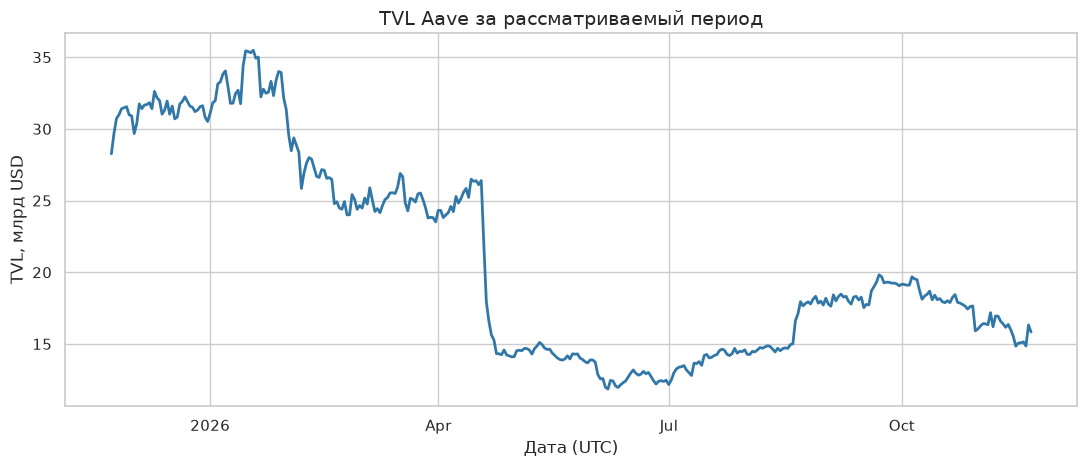

Самое сильное дневное снижение в серии — **-18.3%** (20.04.2026). Апрельский перелом виден в исходном API; данные не сглаживались. По одному ряду TVL нельзя достоверно установить причину этого движения или исключить изменения методологии источника.

TVL Aave изменился с **28.27** до **15.84 млрд USD**, то есть на **-44.0%**. Максимум в доступной серии: **35.48 млрд USD** (18.01.2026).

In [4]:
def growth(series):
    return (series.iloc[-1]/series.iloc[0]-1)*100

fig, ax = plt.subplots()
ax.plot(tvl.index, tvl['Aave']/1e9, color='#3178a8', linewidth=2)
ax.set(title='TVL Aave за рассматриваемый период', ylabel='TVL, млрд USD')
save_plot(fig, '01_aave_tvl.png', ax)
daily_tvl_change = tvl['Aave'].pct_change(fill_method=None)*100
worst_date = daily_tvl_change.idxmin()
display(Markdown(f"Самое сильное дневное снижение в серии — **{daily_tvl_change.loc[worst_date]:.1f}%** ({worst_date:%d.%m.%Y}). Апрельский перелом виден в исходном API; данные не сглаживались. По одному ряду TVL нельзя достоверно установить причину этого движения или исключить изменения методологии источника."))
display(Markdown(f"TVL Aave изменился с **{common['Aave'].iloc[0]/1e9:.2f}** до **{common['Aave'].iloc[-1]/1e9:.2f} млрд USD**, то есть на **{growth(common['Aave']):+.1f}%**. Максимум в доступной серии: **{tvl['Aave'].max()/1e9:.2f} млрд USD** ({tvl['Aave'].idxmax():%d.%m.%Y})."))

## 4. Сравнение с Compound и Morpho

Сравниваем родительские серии трёх Lending-протоколов на одной шкале и одинаковых датах.
Доля ниже относится только к выбранной тройке и не является долей всего рынка Lending.
Parent TVL Morpho берётся как опубликован DeFiLlama: не складываем его с TVL собственных vaults
или других протоколов, чтобы не добавлять двойной счёт вручную.

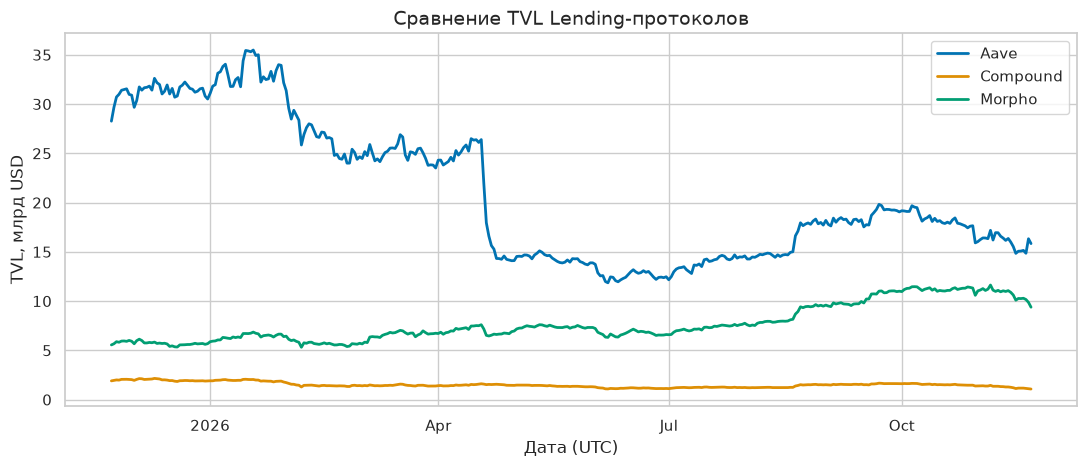

,start_tvl_billion_usd,end_tvl_billion_usd,growth_pct,share_of_three_pct
Aave,28.265,15.837,-43.970,60.232
Compound,1.902,1.074,-43.511,4.086
Morpho,5.552,9.382,68.989,35.682


На последнюю общую дату TVL Aave в **1.69 раза** больше Morpho и в **14.74 раза** больше Compound. Лидер по темпу изменения TVL в выбранной тройке: **Morpho**.

In [5]:
fig, ax = plt.subplots()
for name in ['Aave','Compound','Morpho']:
    ax.plot(common.index, common[name]/1e9, label=name, linewidth=2)
ax.set(title='Сравнение TVL Lending-протоколов', ylabel='TVL, млрд USD')
ax.legend()
save_plot(fig, '02_competitors_tvl.png', ax)

competitors = pd.DataFrame({
    'start_tvl_billion_usd':common[['Aave','Compound','Morpho']].iloc[0]/1e9,
    'end_tvl_billion_usd':common[['Aave','Compound','Morpho']].iloc[-1]/1e9,
    'growth_pct':common[['Aave','Compound','Morpho']].apply(growth),
})
competitors['share_of_three_pct'] = competitors['end_tvl_billion_usd']/competitors['end_tvl_billion_usd'].sum()*100
display(competitors)
competitors.to_csv(DATA/'competitor_summary.csv')
display(Markdown(f"На последнюю общую дату TVL Aave в **{common['Aave'].iloc[-1]/common['Morpho'].iloc[-1]:.2f} раза** больше Morpho и в **{common['Aave'].iloc[-1]/common['Compound'].iloc[-1]:.2f} раза** больше Compound. Лидер по темпу изменения TVL в выбранной тройке: **{competitors['growth_pct'].idxmax()}**."))

## 5. Цена AAVE

AAVE — рыночный токен протокола. Его цена отражает сделки участников рынка и не равна стоимости
активов, внесённых в Aave. Используем дневные наблюдения CoinGecko, без сглаживания и прогноза.

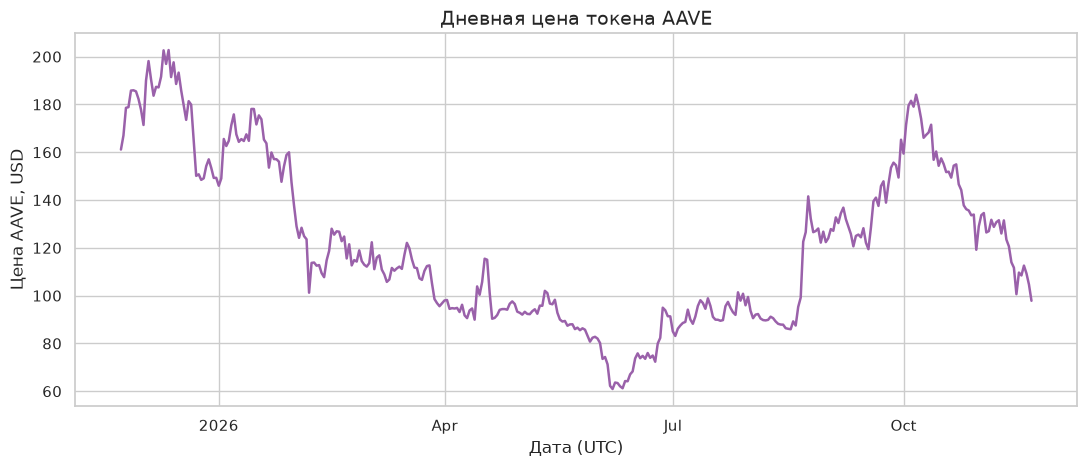

Цена изменилась с **161.12** до **97.85 USD** (**-39.3%**). В дневной серии минимум — **60.93 USD**, максимум — **202.75 USD**.

In [6]:
fig, ax = plt.subplots()
ax.plot(market.index, market['price_usd'], color='#9a61aa', linewidth=1.8)
ax.set(title='Дневная цена токена AAVE', ylabel='Цена AAVE, USD')
save_plot(fig, '03_aave_price.png', ax)
display(Markdown(f"Цена изменилась с **{common['price_usd'].iloc[0]:.2f}** до **{common['price_usd'].iloc[-1]:.2f} USD** (**{growth(common['price_usd']):+.1f}%**). В дневной серии минимум — **{market['price_usd'].min():.2f} USD**, максимум — **{market['price_usd'].max():.2f} USD**."))

## 6. Капитализация и объёмы торгов

Капитализация — рыночная стоимость обращающихся токенов. Она отличается от общей эмиссии,
которую проверим через RPC. Столбцы показывают сообщаемый CoinGecko объём за последние 24 часа
на дату наблюдения. Это не объём выдачи кредитов Aave. Разные шкалы вынесены на два отдельных поля.

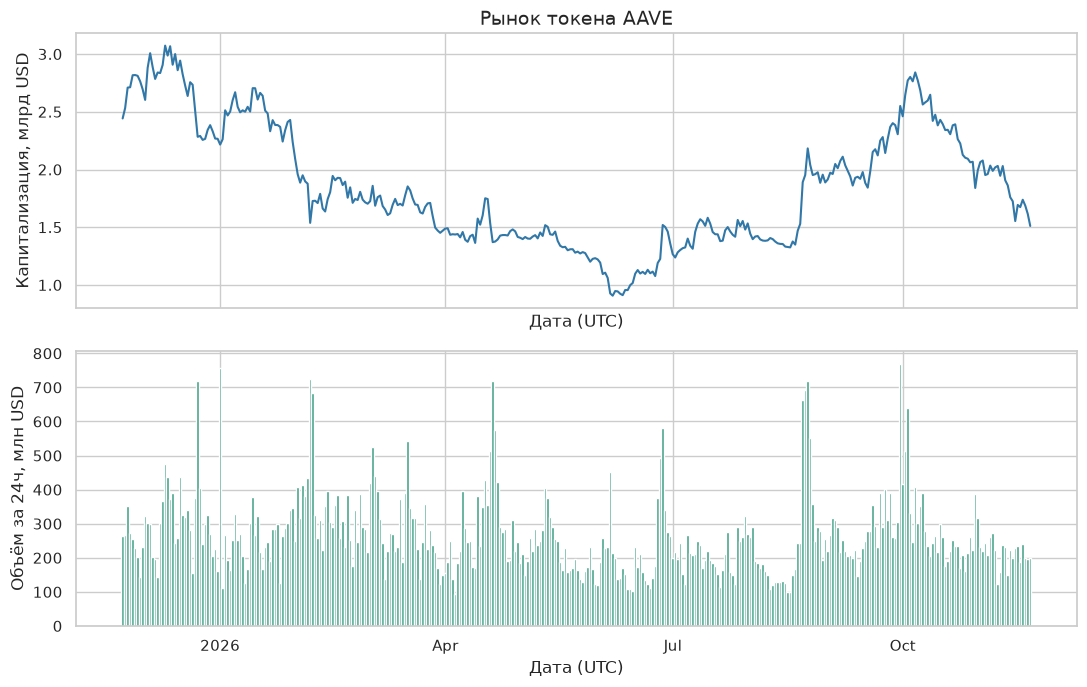

На последнюю дату капитализация — **1.51 млрд USD**. Медианный 24-часовой объём за период — **244.5 млн USD**. Разовый пик объёма не доказывает рост использования кредитного протокола.

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
axes[0].plot(market.index, market['market_cap_usd']/1e9, color='#3178a8')
axes[0].set(title='Рынок токена AAVE', ylabel='Капитализация, млрд USD')
axes[1].bar(market.index, market['volume_24h_usd']/1e6, width=1, color='#47a48b')
axes[1].set_ylabel('Объём за 24ч, млн USD')
save_plot(fig, '04_market_cap_volume.png', axes)
display(Markdown(f"На последнюю дату капитализация — **{market['market_cap_usd'].iloc[-1]/1e9:.2f} млрд USD**. Медианный 24-часовой объём за период — **{market['volume_24h_usd'].median()/1e6:.1f} млн USD**. Разовый пик объёма не доказывает рост использования кредитного протокола."))

## 7. Основные блокчейны

Оставляем только реальные сети: исключаем отдельные категории `borrowed`, `staking`, `pool2`
и их суффиксы. Выбираем пять крупнейших сетей на последнюю общую дату; остальные объединяем.
До первой записи новой сети считаем её TVL нулевым в этой истории. Внутренние пропуски
не заполняем: при их наличии проверка остановит расчёт. Сумму сетей сверяем с TVL Aave.

Максимальное расхождение суммы сетей с общим TVL: 0.0000%


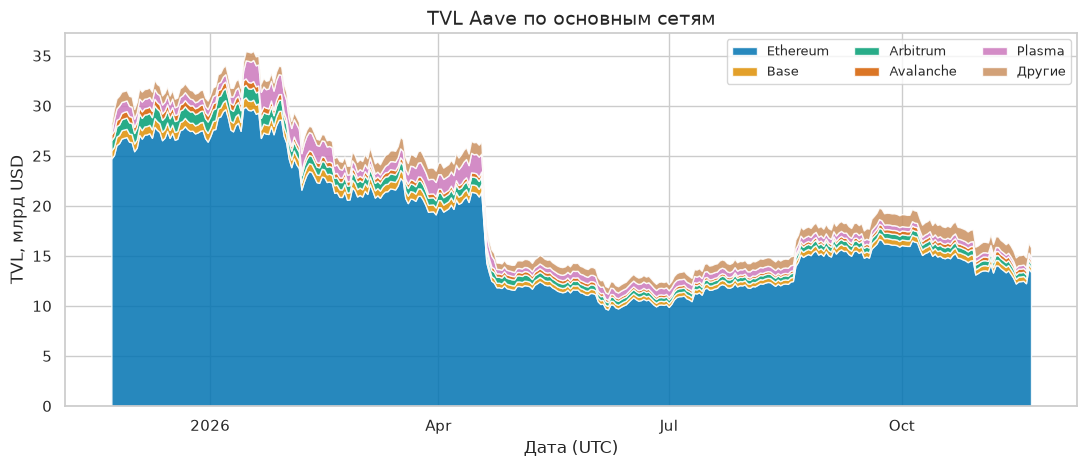

,"Доля TVL, %"
Ethereum,84.645
Base,2.739
Arbitrum,2.411
Avalanche,2.215
Plasma,1.954
Monad,1.424
Arc,1.108
BSC,1.000
X Layer,0.938
Polygon,0.750


Крупнейшая сеть — **Ethereum**, её доля — **84.6%**. На пять крупнейших сетей приходится **94.0%** TVL. Это показывает концентрацию средств, но само по себе не измеряет безопасность сетей.

In [8]:
excluded = {'borrowed','staking','pool2','vesting','offers','doublecounted'}
chain_series = []
for name,body in protocol_data['Aave']['chainTvls'].items():
    if name.lower() in excluded or name.lower().rsplit('-',1)[-1] in excluded:
        continue
    series = daily_series(body['tvl'], 'totalLiquidityUSD', name)
    if len(series):
        aligned = series.reindex(common.index)
        aligned.loc[aligned.index < series.index.min()] = 0
        chain_series.append(aligned)
chains = pd.concat(chain_series, axis=1)
assert not chains.isna().any().any(), 'В истории сетей есть пропуски'
relative_error = (chains.sum(axis=1)-common['Aave']).abs()/common['Aave']
print('Максимальное расхождение суммы сетей с общим TVL:', f'{relative_error.max():.4%}')
assert relative_error.max() < 0.005

chain_shares = (chains.iloc[-1]/common['Aave'].iloc[-1]*100).sort_values(ascending=False)
top_chains = list(chain_shares.head(5).index)
chain_plot = chains[top_chains].copy()
chain_plot['Другие'] = chains.drop(columns=top_chains).sum(axis=1)
fig, ax = plt.subplots()
ax.stackplot(chain_plot.index, *[chain_plot[c]/1e9 for c in chain_plot], labels=chain_plot.columns, alpha=0.85)
ax.set(title='TVL Aave по основным сетям', ylabel='TVL, млрд USD')
ax.legend(loc='upper right', ncol=3, fontsize=9)
save_plot(fig, '05_chain_tvl.png', ax)
display(chain_shares.head(10).rename('Доля TVL, %').to_frame())
chains.to_csv(DATA/'aave_chain_tvl.csv')
chain_shares.rename('share_pct').to_csv(DATA/'chain_shares.csv')
display(Markdown(f"Крупнейшая сеть — **{chain_shares.index[0]}**, её доля — **{chain_shares.iloc[0]:.1f}%**. На пять крупнейших сетей приходится **{chain_shares.head(5).sum():.1f}%** TVL. Это показывает концентрацию средств, но само по себе не измеряет безопасность сетей."))

## 8. TVL и цена AAVE на общей базе

Обе серии приведены к 100 на первую общую дату: `индекс = значение / первое значение × 100`.
Так можно сравнить относительное изменение показателей с разными единицами измерения.
Совпадение или расхождение линий не доказывает причинную связь. Не рассчитываем корреляцию
уровней, чтобы не создавать впечатление надёжной статистической зависимости.

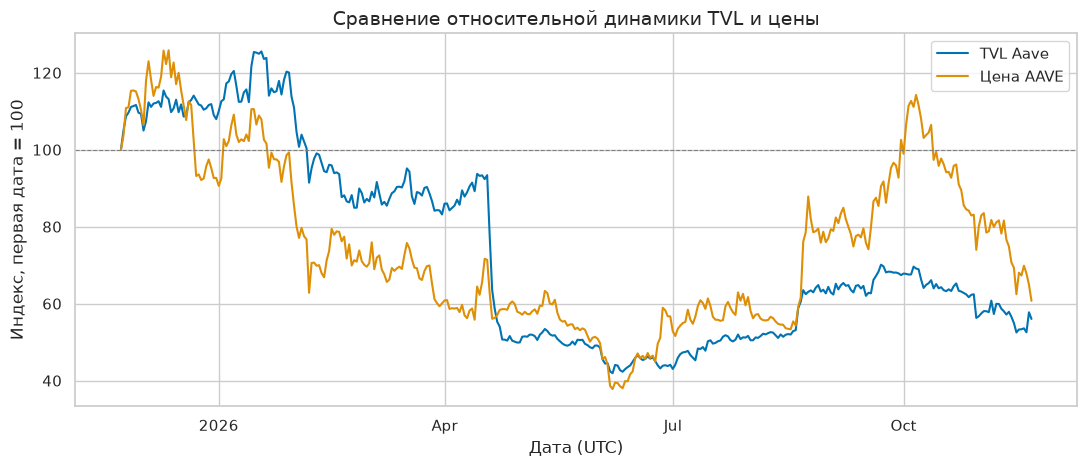

На конец периода индекс TVL равен **56.0**, индекс цены — **60.7**. Разница темпов изменения составляет **-4.7 процентного пункта**. Экономическая активность протокола и результат владения его токеном могут различаться.

In [9]:
indexed = common[['Aave','price_usd']].div(common[['Aave','price_usd']].iloc[0])*100
fig, ax = plt.subplots()
ax.plot(indexed.index, indexed['Aave'], label='TVL Aave')
ax.plot(indexed.index, indexed['price_usd'], label='Цена AAVE')
ax.axhline(100, color='grey', linewidth=0.8, linestyle='--')
ax.set(title='Сравнение относительной динамики TVL и цены', ylabel='Индекс, первая дата = 100')
ax.legend()
save_plot(fig, '06_indexed_growth.png', ax)
display(Markdown(f"На конец периода индекс TVL равен **{indexed['Aave'].iloc[-1]:.1f}**, индекс цены — **{indexed['price_usd'].iloc[-1]:.1f}**. Разница темпов изменения составляет **{growth(common['Aave'])-growth(common['price_usd']):+.1f} процентного пункта**. Экономическая активность протокола и результат владения его токеном могут различаться."))

## 9. Ончейн-данные из трёх дополнительных инструментов

**The Graph:** `liquidityRate / 10**27 × 100` — годовая ставка поставщика APR, а не APY.
Это первые реальные обновления m.USDC в недельных окнах в сети Metis, не средние ставки
и не характеристика всех рынков Aave. Ставки заимствования считаем тем же способом.

**web3.py:** читаем остаток AAVE на контракте aAAVE в Ethereum в начале каждого месяца
и на границах периода. Блоки найдены через DeFiLlama Block API; сами значения получены через
Ethereum RPC. Сохраняем номера, хеши и timestamps блоков. Это ликвидность одного актива;
использовать её как общий TVL нельзя. Историческая эмиссия нужна для проверки единиц и масштаба.

**Etherscan:** смотрим методы в одной открытой странице последних транзакций к контракту AAVE.
Это ограниченная выборка: Approval не равен выдаче кредита; прямые вызовы токена не охватывают
все операции протокола или все Transfer events. Не распространяем частоты выборки на год.

Недельных окон без наблюдения: 3
Subgraph indexed block / timestamp: {'block': {'number': 23448980, 'timestamp': 1795346203}, 'hasIndexingErrors': False}
Данные The Graph: 49 наблюдений; 2025-11-23 02:33:17 — 2026-11-15 11:58:45
web3.py: наблюдений 14 ; эмиссия AAVE: 16000000.0 — 16000000.0
Etherscan: транзакций 18 ; период выборки: 2026-11-22 11:01:23+00:00 — 2026-11-22 11:11:11+00:00


,date,block_number,total_supply_aave,aave_v3_cash_aave
0,2025-11-22 23:59:59,23857896,"16,000,000.000","1,123,548.743"
1,2025-11-30 23:59:59,23914920,"16,000,000.000","1,178,435.514"
2,2025-12-31 23:59:59,24136052,"16,000,000.000","1,203,706.946"
3,2026-01-31 23:59:59,24358292,"16,000,000.000","1,209,393.759"
4,2026-02-28 23:59:59,24558867,"16,000,000.000","955,777.404"


,tx_hash,block_number,timestamp_utc,method
0,0x0cbf465be34d7cdc51d6183110ee14a9fa83a2b23233...,26470271,2026-11-22 11:11:11+00:00,Transfer
1,0x65b93d2ec0a13482ab32d94091370fa49e2b79ed4d08...,26470271,2026-11-22 11:11:11+00:00,Transfer
2,0x7e7e3822ffdad6bd1bf0c1ffe4d676888000f8a6caf1...,26470269,2026-11-22 11:10:47+00:00,Transfer
3,0x49928a377ec5888ffee9985f8c43540bc9ca7ac00a71...,26470262,2026-11-22 11:09:23+00:00,Transfer
4,0x5c8df96708daba04c5d5fdf5b76a5057871b1bfc1445...,26470261,2026-11-22 11:09:11+00:00,Transfer


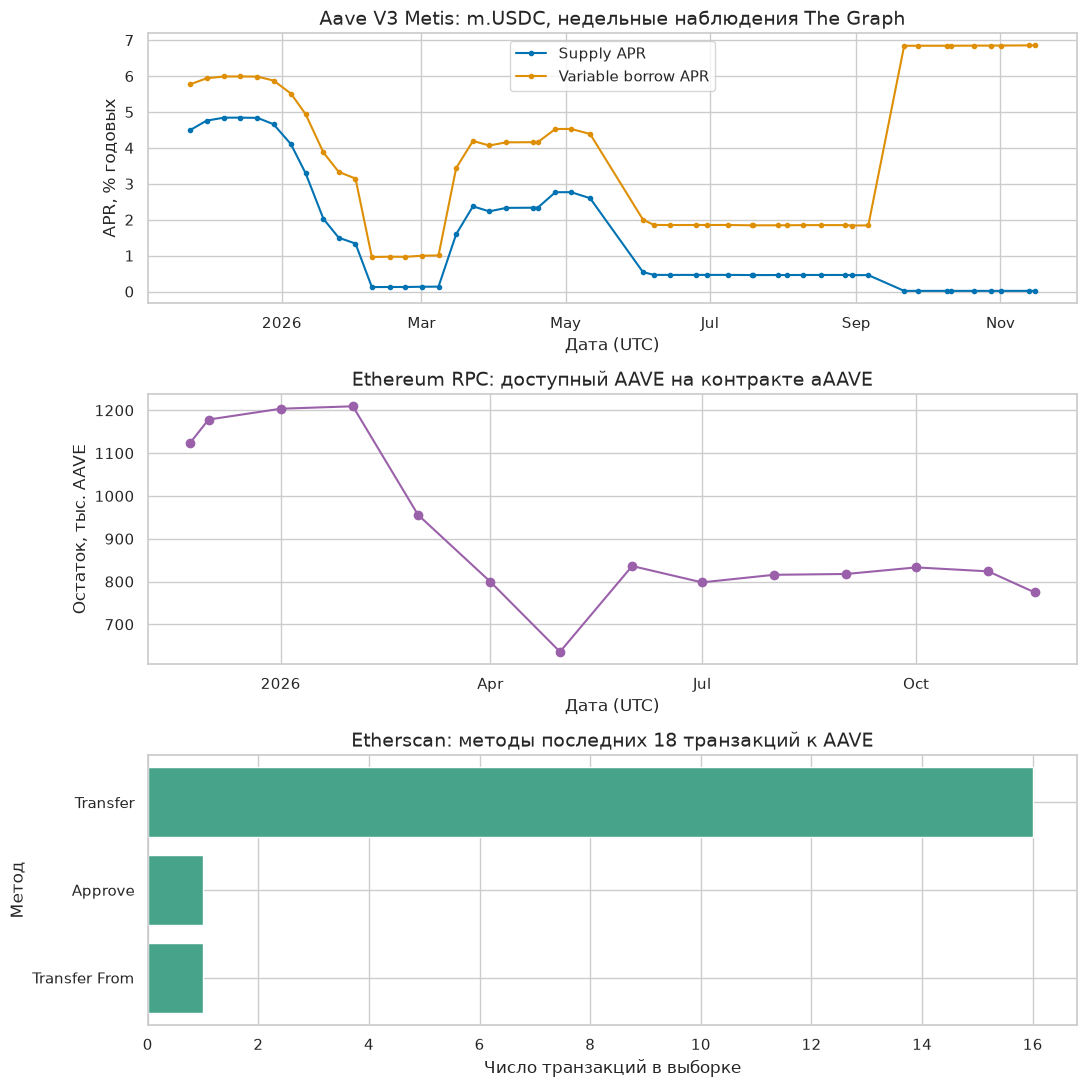

In [10]:
graph = pd.read_csv(DATA/'graph_metis_usdc.csv')
graph['date'] = pd.to_datetime(graph['timestamp'], unit='s', utc=True).dt.tz_localize(None)
graph = graph.sort_values('date').drop_duplicates('id')
# RAY превышает int64: сначала используем целые Python, затем делим для графика.
graph['supply_apr_pct'] = graph['liquidityRate'].map(lambda x: int(x)/10**27*100)
graph['borrow_apr_pct'] = graph['variableBorrowRate'].map(lambda x: int(x)/10**27*100)
rpc = pd.read_csv(DATA/'web3_monthly.csv')
rpc['date'] = pd.to_datetime(rpc['block_timestamp'], unit='s', utc=True).dt.tz_localize(None)
tx = pd.read_csv(DATA/'etherscan_transactions.csv')
tx['timestamp_utc'] = pd.to_datetime(tx['timestamp_utc'], utc=True)
assert len(graph) >= 20 and len(rpc) >= 12 and len(tx) > 0
assert graph['date'].between(START, pd.Timestamp('2026-11-22'), inclusive='left').all()
assert graph[['supply_apr_pct','borrow_apr_pct']].ge(0).all().all()
assert rpc['total_supply_aave'].between(0, 16_000_000).all()
assert (rpc['aave_v3_cash_aave'] <= rpc['total_supply_aave']).all()
meta = read_json('graph_reserves.json')['data']['_meta']
assert not meta['hasIndexingErrors']
print('Недельных окон без наблюдения:', len(pd.date_range(START, END, freq='7D'))-len(graph))
print('Subgraph indexed block / timestamp:', meta)
print('Данные The Graph:', len(graph), 'наблюдений;', graph['date'].min(), '—', graph['date'].max())
print('web3.py: наблюдений', len(rpc), '; эмиссия AAVE:', rpc['total_supply_aave'].min(), '—', rpc['total_supply_aave'].max())
print('Etherscan: транзакций', len(tx), '; период выборки:', tx['timestamp_utc'].min(), '—', tx['timestamp_utc'].max())
display(rpc[['date','block_number','total_supply_aave','aave_v3_cash_aave']].head())
display(tx.head())

fig, axes = plt.subplots(3, 1, figsize=(11, 11))
axes[0].plot(graph['date'], graph['supply_apr_pct'], marker='.', label='Supply APR')
axes[0].plot(graph['date'], graph['borrow_apr_pct'], marker='.', label='Variable borrow APR')
axes[0].set(title='Aave V3 Metis: m.USDC, недельные наблюдения The Graph', ylabel='APR, % годовых')
axes[0].legend()
axes[1].plot(rpc['date'], rpc['aave_v3_cash_aave']/1000, marker='o', color='#9a61aa')
axes[1].set(title='Ethereum RPC: доступный AAVE на контракте aAAVE', ylabel='Остаток, тыс. AAVE')
methods = tx['method'].value_counts().head(5).sort_values()
axes[2].barh(methods.index, methods.values, color='#47a48b')
axes[2].set(title=f'Etherscan: методы последних {len(tx)} транзакций к AAVE', xlabel='Число транзакций в выборке', ylabel='Метод')
axes[2].xaxis.set_major_locator(plt.MaxNLocator(integer=True))
save_plot(fig, '07_onchain.png', axes[:2])
graph.to_csv(DATA/'graph_rates_clean.csv', index=False)

## 10. Итог и воспроизводимость

Ниже автоматически сохраняем показатели и небольшой отчёт, чтобы выводы соответствовали
приложенным данным. Ограничения: долларовая переоценка влияет на TVL; снимки разных API
не синхронизированы до секунды; subgraph охватывает один рынок Metis; Etherscan даёт лишь
последние прямые вызовы; месячные RPC-снимки не показывают внутримесячную динамику.
Публичный Dune dashboard — дополнительное задание, здесь не создавался.

Код загрузки, исходные ответы, CSV и графики сохранены. Минимальный локальный MCP-сервер
читает готовые результаты; он не заменяет пять источников и не нужен для запуска расчётов.
Настройка и проверка описаны в `MCP_SETUP.md`, использование ИИ и журнал — в `LLM_USAGE.md`.

In [11]:
summary = {
    'period_start':str(common.index.min().date()), 'period_end':str(common.index.max().date()),
    'daily_observations':len(common),
    'aave_v3_defillama_rank':int(aave_rank['rank'].iloc[0]),
    'aave_tvl_start_usd':float(common['Aave'].iloc[0]), 'aave_tvl_end_usd':float(common['Aave'].iloc[-1]),
    'aave_tvl_change_pct':float(growth(common['Aave'])),
    'aave_price_start_usd':float(common['price_usd'].iloc[0]), 'aave_price_end_usd':float(common['price_usd'].iloc[-1]),
    'aave_price_change_pct':float(growth(common['price_usd'])),
    'chain_shares_pct':chain_shares.to_dict(),
    'competitors':competitors.to_dict(orient='index'),
    'graph_observations':len(graph), 'rpc_observations':len(rpc), 'etherscan_sample_transactions':len(tx),
    'etherscan_sample_start':str(tx['timestamp_utc'].min()), 'etherscan_sample_end':str(tx['timestamp_utc'].max()),
    'metis_supply_apr_median_pct':float(graph['supply_apr_pct'].median()),
    'web3_cash_first_aave':float(rpc['aave_v3_cash_aave'].iloc[0]),
    'web3_cash_last_aave':float(rpc['aave_v3_cash_aave'].iloc[-1]),
    'sources_used':['DeFiLlama','CoinGecko','Etherscan (HTML)','web3.py','The Graph (Metis subgraph on 0xGraph)'],
}
(DATA/'results_summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
competitor_lines = '\n'.join(f"| {name} | {row['start_tvl_billion_usd']:.2f} | {row['end_tvl_billion_usd']:.2f} | {row['growth_pct']:+.1f}% | {row['share_of_three_pct']:.1f}% |" for name,row in competitors.iterrows())
chain_text = ', '.join(f'{name}: {value:.1f}%' for name,value in chain_shares.head(5).items())
report = f"""# Итоговый отчёт DeFi EDA Aave

Исследован Lending-протокол Aave за {summary['period_start']}–{summary['period_end']}, {len(common)} общих дневных наблюдений. Данные загружены 22.11.2026. Aave V3 занимает место {summary['aave_v3_defillama_rank']} среди записей DeFiLlama после исключения категории CEX, что удовлетворяет условию top-50. Основной анализ относится к семейству Aave.

## Результаты

TVL Aave изменился с {summary['aave_tvl_start_usd']/1e9:.2f} до {summary['aave_tvl_end_usd']/1e9:.2f} млрд USD ({summary['aave_tvl_change_pct']:+.1f}%). Цена AAVE изменилась с {summary['aave_price_start_usd']:.2f} до {summary['aave_price_end_usd']:.2f} USD ({summary['aave_price_change_pct']:+.1f}%). Разница темпов равна {summary['aave_tvl_change_pct']-summary['aave_price_change_pct']:+.1f} п.п. Стоимость токена и ликвидность протокола имеют разную динамику.

| Протокол | TVL в начале, млрд USD | TVL в конце, млрд USD | Изменение | Доля тройки в конце |
|---|---:|---:|---:|---:|
{competitor_lines}

По относительному изменению TVL лидирует {competitors['growth_pct'].idxmax()}. На последнюю общую дату Aave больше Morpho в {common['Aave'].iloc[-1]/common['Morpho'].iloc[-1]:.2f} раза, Compound — в {common['Aave'].iloc[-1]/common['Compound'].iloc[-1]:.2f} раза. Доли рассчитаны только для этой тройки.

Основные сети Aave на конец периода: {chain_text}. Пять крупнейших сетей составляют {chain_shares.head(5).sum():.1f}% TVL. Крупнейшая сеть — {chain_shares.index[0]}, поэтому распределение ликвидности по сетям существенно неравномерно.

Медианный 24-часовой торговый объём AAVE — {market['volume_24h_usd'].median()/1e6:.1f} млн USD. Это рыночная торговля токеном, не кредитный оборот Aave.

## Ончейн-наблюдения

Для The Graph проверено недельных окон: {len(pd.date_range(START, END, freq='7D'))}; окна без наблюдений не заполнялись. Etherscan описывает отдельную короткую выборку на дату загрузки, не годовой ряд.

The Graph дал {len(graph)} реальных недельных наблюдений ставок m.USDC Aave V3 Metis. Медианная наблюдаемая supply APR составила {graph['supply_apr_pct'].median():.3f}%. Это отдельный небольшой рынок, результаты не распространяются на весь Aave.

Через web3.py выполнены исторические eth_call для {len(rpc)} блоков Ethereum. Доступный остаток AAVE на aAAVE изменился с {rpc['aave_v3_cash_aave'].iloc[0]:,.0f} до {rpc['aave_v3_cash_aave'].iloc[-1]:,.0f} AAVE. Это остаток одного резерва без пересчёта в USD, не TVL всего протокола.

Etherscan: получена открытая HTML-выборка из {len(tx)} последних транзакций к контракту токена, от {tx['timestamp_utc'].min()} до {tx['timestamp_utc'].max()}. Частоты методов описывают только выборку. Полная история Transfer events не собиралась. REST API без ключа недоступен.

## Источники и ограничения

Наиболее сильное дневное снижение TVL составило {daily_tvl_change.loc[worst_date]:.1f}% ({worst_date:%d.%m.%Y}). Апрельский перелом присутствует в исходном API; данные не сглаживались. По одному TVL-ряду нельзя установить причину или исключить изменение методологии источника.

Реально использованы пять инструментов: DeFiLlama REST API, CoinGecko REST API, Etherscan HTML, web3.py через Ethereum RPC и subgraph The Graph Aave V3 Metis на 0xGraph. Последний указан в официальном репозитории Aave; это не The Graph Network gateway. Все исходные ответы сохранены, искусственных значений нет. Dune dashboard — дополнительный пункт, не выполнен.

TVL включает ценовую переоценку, поэтому его изменение не равно притоку капитала. Исключены borrowed/staking/pool2; parent-серии не складывались с дочерними версиями. Пропуски между источниками не интерполировались. До первой записи новой сети в истории её вклад принят нулевым. API-снимки внутри одной UTC-даты не обязательно одновременны.

Созданы семь рисунков в plots/; расчёты и пояснения находятся в analysis.ipynb. Проверки контролируют ключевые пропуски, уникальность дат, положительность значений и согласование суммы сетей с TVL (максимальное расхождение {relative_error.max():.4%}). MCP и прозрачность ИИ описаны в MCP_SETUP.md и LLM_USAGE.md.

Источники: [DeFiLlama API](https://api.llama.fi/protocol/aave), [определения TVL](https://docs.llama.fi/analysts/data-definitions), [CoinGecko API](https://docs.coingecko.com/reference/coins-id-market-chart), [Etherscan](https://etherscan.io/token/0x7fc66500c84a76ad7e9c93437bfc5ac33e2ddae9), [Aave subgraphs](https://github.com/aave/protocol-subgraphs), [адреса Aave](https://github.com/bgd-labs/aave-address-book), [web3.py](https://web3py.readthedocs.io/en/stable/).
"""
(ROOT/'REPORT.md').write_text(report, encoding='utf-8')
display(Markdown(report))
print('Сохранено рисунков:', len(list(PLOTS.glob('*.png'))))
assert len(list(PLOTS.glob('*.png'))) == 7

# Итоговый отчёт DeFi EDA Aave

Исследован Lending-протокол Aave за 2025-11-23–2026-11-21, 364 общих дневных наблюдений. Данные загружены 22.11.2026. Aave V3 занимает место 3 среди записей DeFiLlama после исключения категории CEX, что удовлетворяет условию top-50. Основной анализ относится к семейству Aave.

## Результаты

TVL Aave изменился с 28.27 до 15.84 млрд USD (-44.0%). Цена AAVE изменилась с 161.12 до 97.85 USD (-39.3%). Разница темпов равна -4.7 п.п. Стоимость токена и ликвидность протокола имеют разную динамику.

| Протокол | TVL в начале, млрд USD | TVL в конце, млрд USD | Изменение | Доля тройки в конце |
|---|---:|---:|---:|---:|
| Aave | 28.27 | 15.84 | -44.0% | 60.2% |
| Compound | 1.90 | 1.07 | -43.5% | 4.1% |
| Morpho | 5.55 | 9.38 | +69.0% | 35.7% |

По относительному изменению TVL лидирует Morpho. На последнюю общую дату Aave больше Morpho в 1.69 раза, Compound — в 14.74 раза. Доли рассчитаны только для этой тройки.

Основные сети Aave на конец периода: Ethereum: 84.6%, Base: 2.7%, Arbitrum: 2.4%, Avalanche: 2.2%, Plasma: 2.0%. Пять крупнейших сетей составляют 94.0% TVL. Крупнейшая сеть — Ethereum, поэтому распределение ликвидности по сетям существенно неравномерно.

Медианный 24-часовой торговый объём AAVE — 244.5 млн USD. Это рыночная торговля токеном, не кредитный оборот Aave.

## Ончейн-наблюдения

Для The Graph проверено недельных окон: 52; окна без наблюдений не заполнялись. Etherscan описывает отдельную короткую выборку на дату загрузки, не годовой ряд.

The Graph дал 49 реальных недельных наблюдений ставок m.USDC Aave V3 Metis. Медианная наблюдаемая supply APR составила 0.464%. Это отдельный небольшой рынок, результаты не распространяются на весь Aave.

Через web3.py выполнены исторические eth_call для 14 блоков Ethereum. Доступный остаток AAVE на aAAVE изменился с 1,123,549 до 774,556 AAVE. Это остаток одного резерва без пересчёта в USD, не TVL всего протокола.

Etherscan: получена открытая HTML-выборка из 18 последних транзакций к контракту токена, от 2026-11-22 11:01:23+00:00 до 2026-11-22 11:11:11+00:00. Частоты методов описывают только выборку. Полная история Transfer events не собиралась. REST API без ключа недоступен.

## Источники и ограничения

Наиболее сильное дневное снижение TVL составило -18.3% (20.04.2026). Апрельский перелом присутствует в исходном API; данные не сглаживались. По одному TVL-ряду нельзя установить причину или исключить изменение методологии источника.

Реально использованы пять инструментов: DeFiLlama REST API, CoinGecko REST API, Etherscan HTML, web3.py через Ethereum RPC и subgraph The Graph Aave V3 Metis на 0xGraph. Последний указан в официальном репозитории Aave; это не The Graph Network gateway. Все исходные ответы сохранены, искусственных значений нет. Dune dashboard — дополнительный пункт, не выполнен.

TVL включает ценовую переоценку, поэтому его изменение не равно притоку капитала. Исключены borrowed/staking/pool2; parent-серии не складывались с дочерними версиями. Пропуски между источниками не интерполировались. До первой записи новой сети в истории её вклад принят нулевым. API-снимки внутри одной UTC-даты не обязательно одновременны.

Созданы семь рисунков в plots/; расчёты и пояснения находятся в analysis.ipynb. Проверки контролируют ключевые пропуски, уникальность дат, положительность значений и согласование суммы сетей с TVL (максимальное расхождение 0.0000%). MCP и прозрачность ИИ описаны в MCP_SETUP.md и LLM_USAGE.md.

Источники: [DeFiLlama API](https://api.llama.fi/protocol/aave), [определения TVL](https://docs.llama.fi/analysts/data-definitions), [CoinGecko API](https://docs.coingecko.com/reference/coins-id-market-chart), [Etherscan](https://etherscan.io/token/0x7fc66500c84a76ad7e9c93437bfc5ac33e2ddae9), [Aave subgraphs](https://github.com/aave/protocol-subgraphs), [адреса Aave](https://github.com/bgd-labs/aave-address-book), [web3.py](https://web3py.readthedocs.io/en/stable/).


Сохранено рисунков: 7
